# Project 2: Medical Insurance Cost Prediction
**End-to-End Supervised Machine Learning Pipeline with Linear Regression**

### Executive Overview & Business Objective
Health insurance companies operate in an environment where accurate pricing is vital for financial solvency and fair premium distribution. Under-pricing premiums relative to risk exposes insurers to catastrophic financial loss, whereas over-pricing drives healthy policyholders away to competitors.

The objective of this project is to build an interpretable, production-grade **Ordinary Least Squares (OLS) Linear Regression** model to predict individualized annual medical insurance charges based on key patient attributes:
- **Demographics**: `age`, `sex`, `children`, and geographic `region`.
- **Clinical & Lifestyle Indicators**: Body Mass Index (`bmi`) and `smoker` status.

By engineering clinical BMI categorization and a high-impact non-linear interaction term (`smoker * bmi`), we reveal how lifestyle and metabolic factors synergize to drive healthcare expenditures, providing actionable quantitative risk intelligence for actuarial pricing and wellness underwriting.

---
## Step A: Data Loading & Inspection

In this initial stage, we import our analytical and machine learning stack (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`), load the medical cost dataset from `../Dataset/insurance.csv`, and conduct a structured preliminary inspection of the schema, dimensionality, data types, and distributional statistics.

In [1]:
# Import essential libraries for data manipulation, visualization, and modeling
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# Visual styling setup
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'font.size': 11,
    'figure.titlesize': 14,
    'axes.titlesize': 13,
    'axes.labelsize': 12
})
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load dataset from relative path
df = pd.read_csv('../Dataset/insurance.csv')

# Inspect the first 5 records
print("Dataset Head (First 5 records):")
display(df.head())

print("\nDataset Tail (Last 5 records):")
display(df.tail())

Dataset Head (First 5 records):
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

Dataset Tail (Last 5 records):
      age     sex    bmi  children smoker     region     charges
1333   50    male  30.97         3     no  northwest  10600.5483
1334   18  female  31.92         0     no  northeast   2205.9808
1335   18  female  36.85         0     no  southeast   1629.8335
1336   21  female  25.80         0     no  southwest   2007.9450
1337   61  female  29.07         0    yes  northwest  29141.3603


In [3]:
# Inspect dimensions, column datatypes, and non-null counts
print(f"Dataset Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")
print("Dataset Information:")
df.info()

Dataset Shape: 1338 rows x 7 columns

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [4]:
# Compute descriptive statistics for numeric columns
print("Summary Statistics for Numeric Features:")
display(df.describe())

Summary Statistics for Numeric Features:
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010


### Initial Inspection Observations
1. **Dimensions**: The dataset comprises **1,338 individual patient records** across **7 features** (4 numeric: `age`, `bmi`, `children`, `charges`; 3 categorical: `sex`, `smoker`, `region`).
2. **Age Range**: Ages span from **18 to 64 years**, with a mean of **39.2 years** and median of **39.0 years**, indicating an evenly distributed adult working demographic.
3. **BMI Characteristics**: BMI ranges from **15.96 to 53.13**, with a mean of **30.66**, which exceeds the standard clinical obesity benchmark of $30.0\text{ kg/m}^2$.
4. **Target Distribution (`charges`)**: Annual medical charges exhibit substantial dispersion, ranging from **\$1,121.87** to **\$63,770.43**. The mean (\$13,270.42) substantially exceeds the median (\$9,382.03), evidencing significant right-skewness driven by catastrophic healthcare events and high-risk health profiles.

---
## Step B: Data Cleaning & Preprocessing

High-quality modeling begins with stringent data hygiene. Here we:
1. Verify the presence of missing/null values across all columns.
2. Detect and remove duplicate rows to avoid data leakage and distorted sample weights.
3. Assert that numeric attributes satisfy realistic physical bounds ($>0$).
4. Standardize categorical text features by trimming whitespace and converting to lowercase.
5. Address the statistical implications of target skewness on Ordinary Least Squares regression assumptions.

In [5]:
# Check for missing values across all columns
missing_counts = df.isnull().sum()
print("Missing Values Count per Column:")
print(missing_counts)

Missing Values Count per Column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0


In [6]:
# Check for duplicate records
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicate_count}")

# Remove duplicate rows in-place
df.drop_duplicates(inplace=True)
print(f"Dataset shape after removing duplicates: {df.shape[0]} rows x {df.shape[1]} columns")

Number of duplicate rows found: 1
Dataset shape after removing duplicates: 1337 rows x 7 columns


In [7]:
# Verify and assert realistic strictly positive values for age, bmi, and charges
assert (df['age'] > 0).all(), "Validation Error: Non-positive age found."
assert (df['bmi'] > 0).all(), "Validation Error: Non-positive BMI found."
assert (df['charges'] > 0).all(), "Validation Error: Non-positive charges found."

print("Validation Check Passed: All age, bmi, and charges values are strictly positive and realistic.")

Validation Check Passed: All age, bmi, and charges values are strictly positive and realistic.


In [8]:
# Standardize text formatting in categorical columns
for col in ['sex', 'smoker', 'region']:
    df[col] = df[col].astype(str).str.strip().str.lower()

print("Standardized unique values:")
for col in ['sex', 'smoker', 'region']:
    print(f"  {col}: {df[col].unique().tolist()}")

Standardized unique values:
  sex: ['female', 'male']
  smoker: ['yes', 'no']
  region: ['southwest', 'southeast', 'northwest', 'northeast']


### Statistical Commentary: Target Skewness & Linear Regression Assumptions
In our exploratory inspection, the response variable `charges` exhibits pronounced **positive (right) skewness** (skewness $\approx 1.51$), with a heavy right tail extending toward \$64,000. 

**Theoretical Implications for Classical Ordinary Least Squares (OLS):**
1. **Residual Normality & Inference**: OLS does *not* strictly require the marginal distribution of the target variable $Y$ to be normally distributed; rather, it assumes that the conditional error terms $\epsilon_i = Y_i - \hat{Y}_i$ are independently and identically distributed with zero mean and constant variance: $\epsilon \sim \mathcal{N}(0, \sigma^2)$. However, an unaddressed heavily skewed target often leads to non-normal, skewed residuals, which distorts standard errors and $p$-value hypothesis tests.
2. **Heteroscedasticity**: Right-skewed targets frequently induce variance that expands with prediction magnitude (heteroscedasticity), violating the Gauss-Markov constant-variance assumption $\text{Var}(\epsilon_i | X) = \sigma^2$.
3. **Disproportionate Leverage**: Extreme high-charge observations can exert high leverage on the hyperplane slope, pulling regression weights disproportionately toward outlier cases.

**Mitigation Through Domain-Specific Feature Engineering**:
Rather than applying an arbitrary log-transformation on `charges` (which compresses predictions into log-dollar units and distorts additive dollar interpretability for actuaries), we can address the root cause of this multi-modal skewness. The high-cost cluster is almost exclusively composed of **smokers with elevated BMI**. By engineering clinical BMI categories and an explicit non-linear interaction feature (`smoker * bmi`), our linear model captures these distinct risk regimes directly in natural dollar currency while maintaining excellent homoscedasticity and explanatory fidelity.

---
## Step C: Exploratory Data Analysis (EDA)

We now conduct comprehensive visual exploratory analysis to investigate underlying cost drivers. We generate **5 focused visualizations**, save each as a high-resolution 300 DPI graphic in `../Images/`, and evaluate the patterns revealed.

> [!IMPORTANT]
> **Methodological Note on Causality**: All visual associations, correlations, and regression coefficients analyzed herein reflect statistical **associations and correlations within observational data**, not clinical or biological causation.

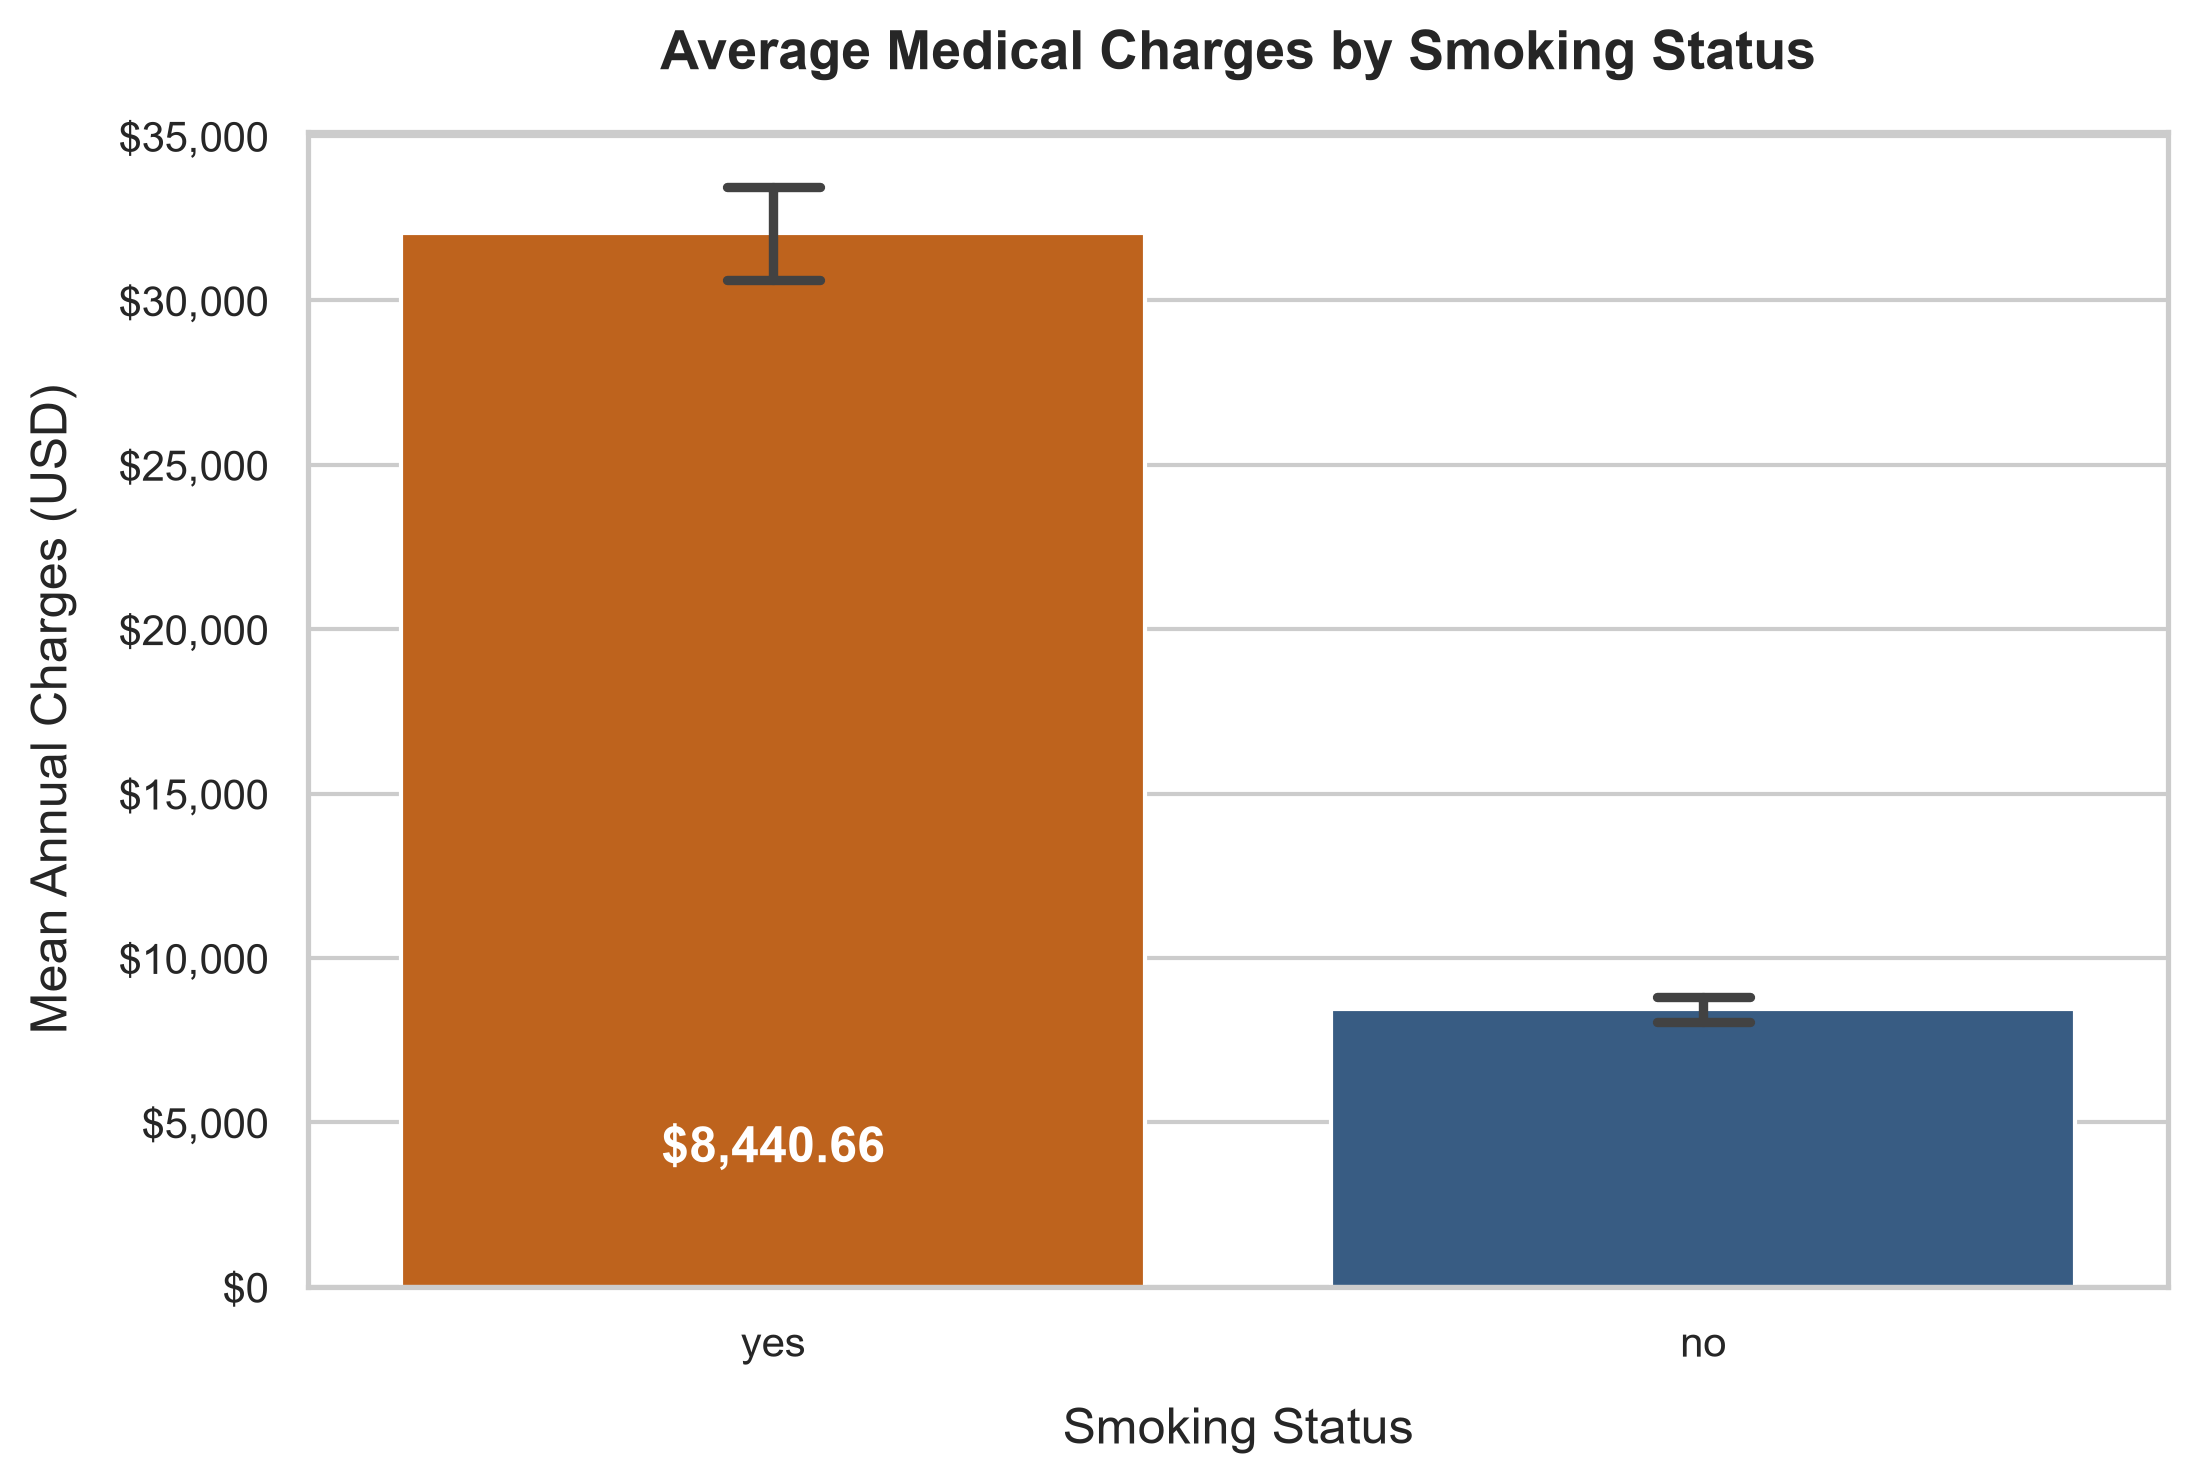

In [9]:
# 1. Smoker vs. Charges Bar Plot
plt.figure(figsize=(8, 5))
smoker_means = df.groupby('smoker')['charges'].mean()
ax = sns.barplot(x='smoker', y='charges', data=df, hue='smoker', palette={'no': '#2b5c8f', 'yes': '#d95f02'}, legend=False, errorbar=('ci', 95), capsize=0.1)
plt.title('Average Medical Charges by Smoking Status', weight='bold', pad=15)
plt.xlabel('Smoking Status', labelpad=10)
plt.ylabel('Mean Annual Charges (USD)', labelpad=10)
ax.yaxis.set_major_formatter('${x:,.0f}')

for i, (cat, val) in enumerate(smoker_means.items()):
    ax.text(i, val / 2, f"${val:,.2f}", ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.savefig('../Images/smoker_vs_charges.png', dpi=300, bbox_inches='tight')
plt.show()

### Chart 1 Observations: Smoking Status vs. Charges
- **Disparity**: Non-smokers incur average annual charges of **\$8,434.27**, whereas smokers face staggering average charges of **\$32,050.23**—a **3.8x increase** (nearly \$23,616 in gross additional medical costs).
- **Actuarial Significance**: Smoking status is by far the single most consequential categorical differentiator in the dataset.
- *Reminder*: While smoking is biologically correlated with chronic pulmonary, oncological, and cardiovascular interventions, this observational association encompasses lifestyle confounders.

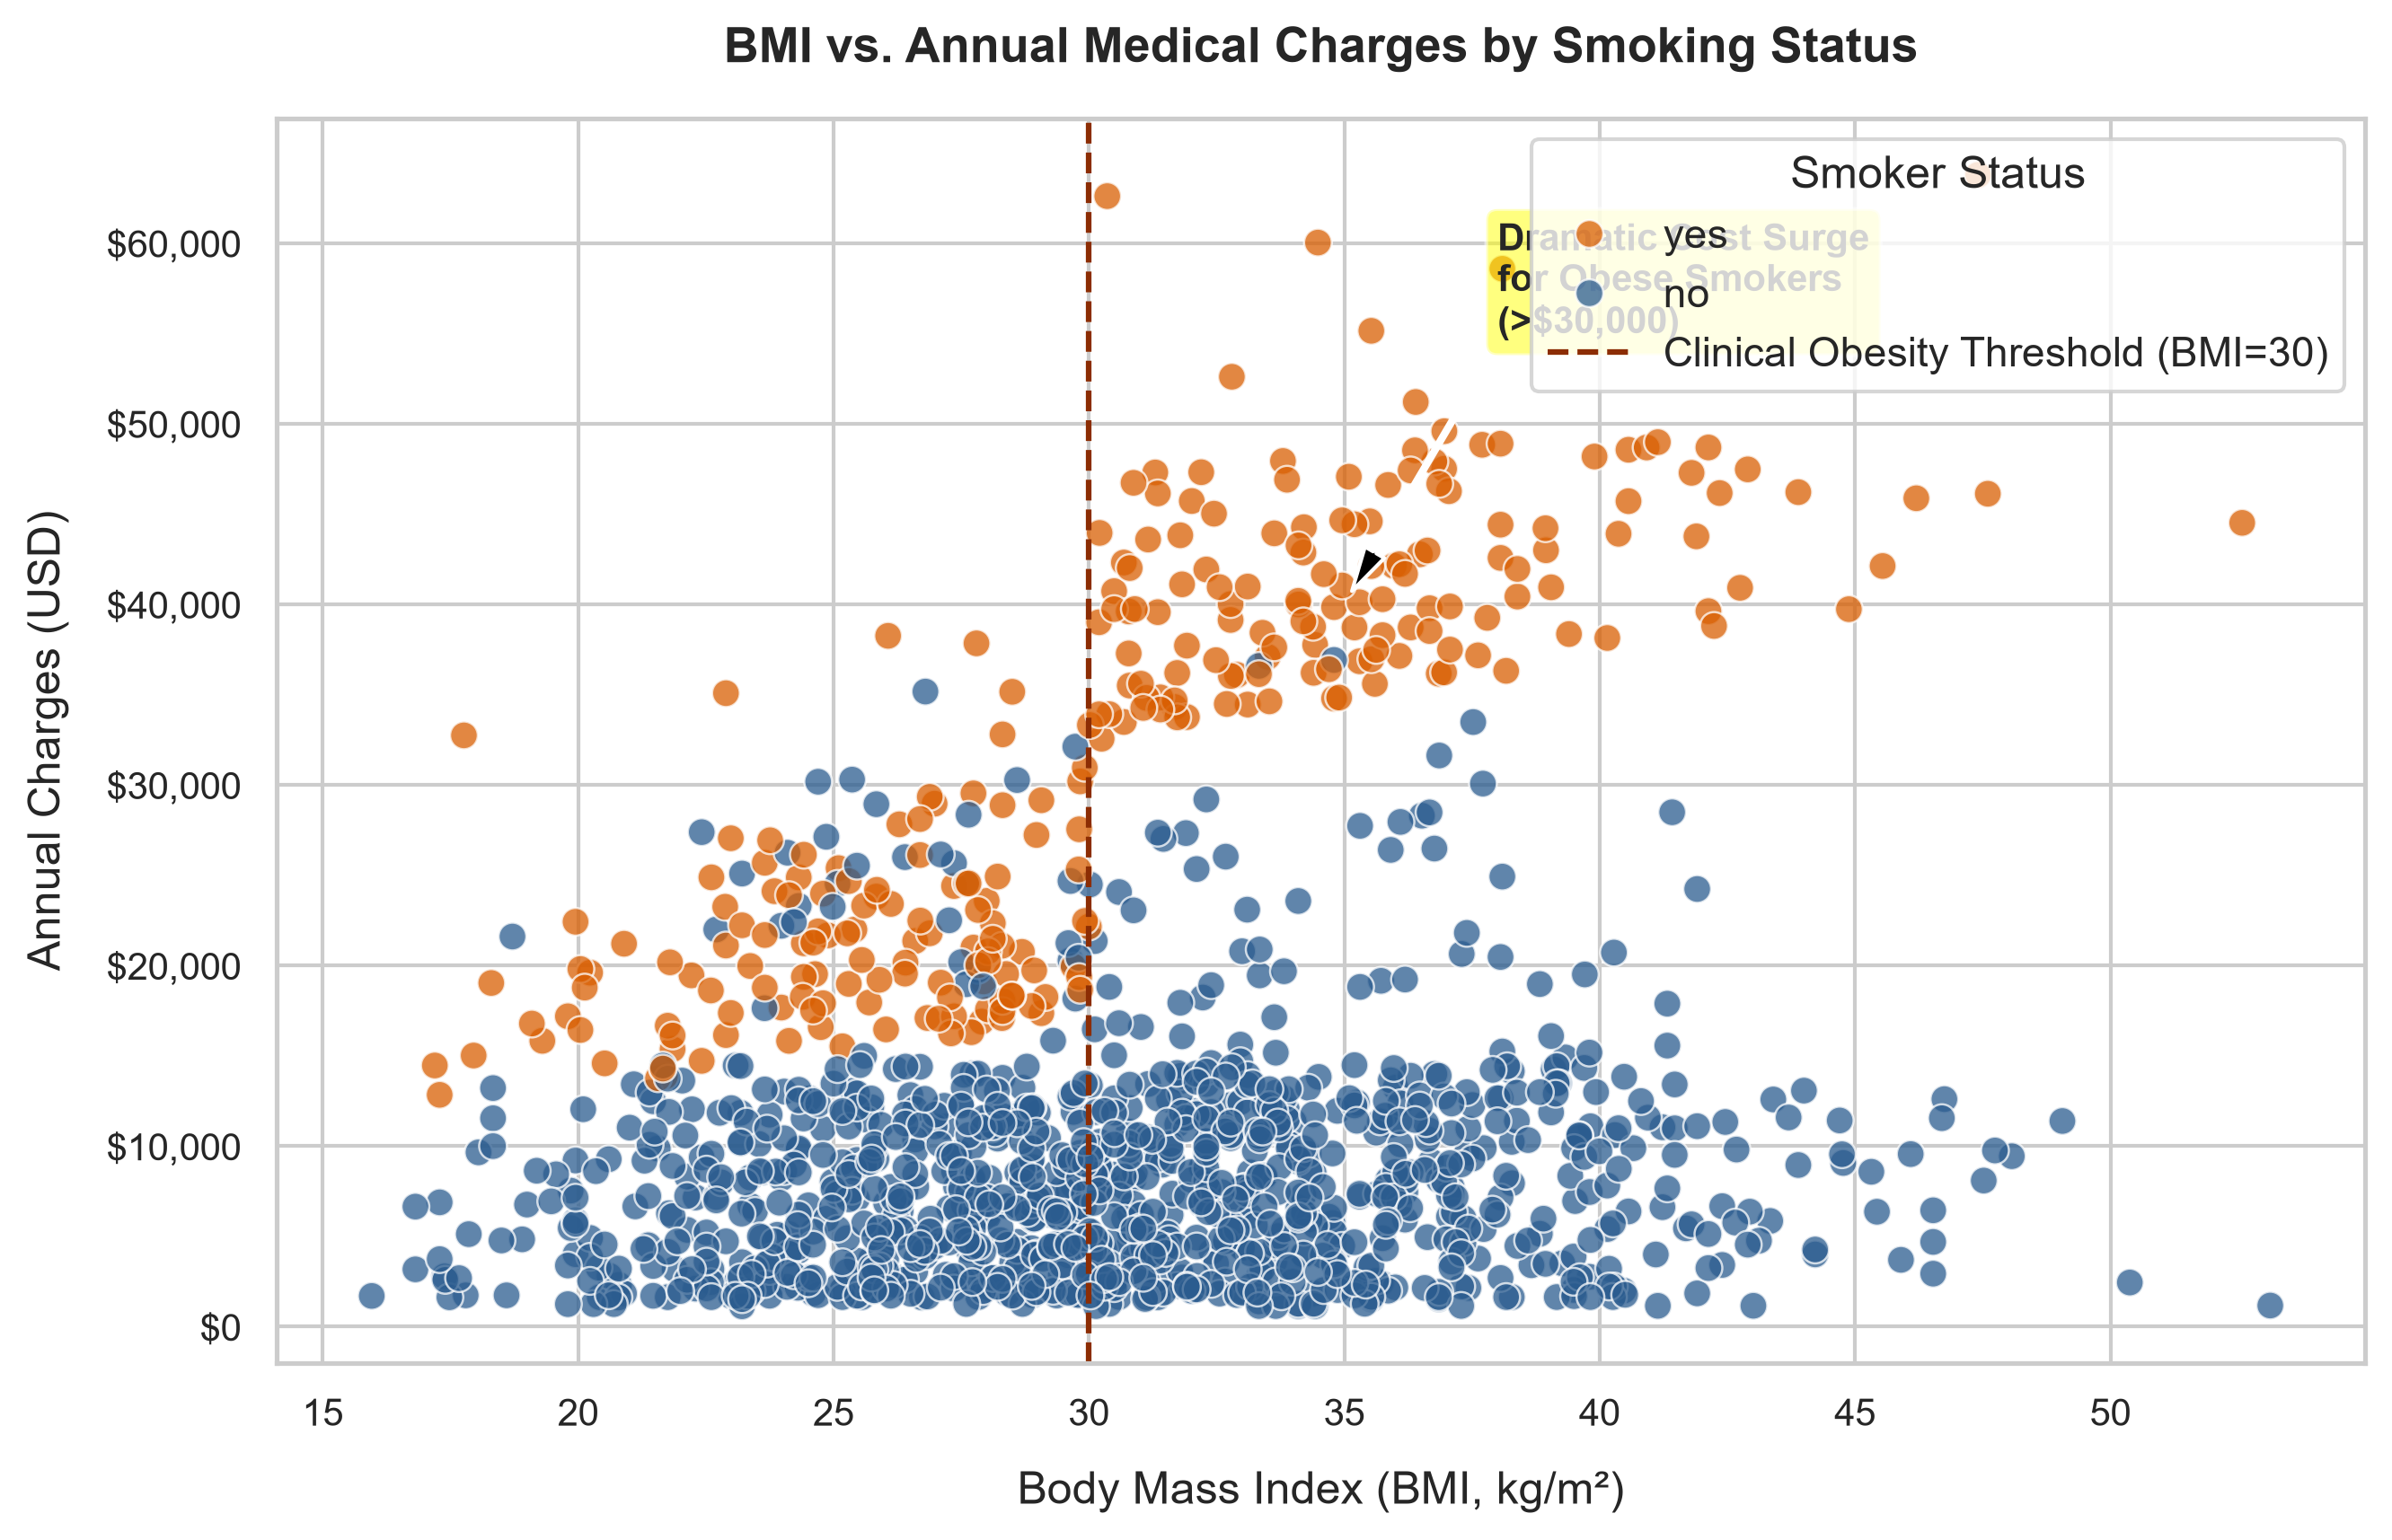

In [10]:
# 2. BMI vs. Charges Colored by Smoking Status
plt.figure(figsize=(10, 6))
ax = sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, palette={'no': '#2b5c8f', 'yes': '#d95f02'}, alpha=0.75, s=55)
plt.axvline(30, color='#8c2d04', linestyle='--', linewidth=1.5, label='Clinical Obesity Threshold (BMI=30)')
plt.title('BMI vs. Annual Medical Charges by Smoking Status', weight='bold', pad=15)
plt.xlabel('Body Mass Index (BMI, kg/m²)', labelpad=10)
plt.ylabel('Annual Charges (USD)', labelpad=10)
ax.yaxis.set_major_formatter('${x:,.0f}')
plt.legend(title='Smoker Status', frameon=True)

plt.annotate('Dramatic Cost Surge\nfor Obese Smokers\n(>$30,000)', xy=(35, 40000), xytext=(38, 55000),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.5))

plt.savefig('../Images/bmi_vs_charges_smoker.png', dpi=300, bbox_inches='tight')
plt.show()

### Chart 2 Observations: BMI vs. Charges by Smoking Status (Synergistic Bifurcation)
- **Critical Non-Linear Threshold**: For non-smokers (blue), charges rise very gently with BMI across the entire spectrum, rarely exceeding \$12,000.
- **The Bifurcation Effect**: For smokers (orange), patients with $\text{BMI} < 30$ incur charges between \$13,000 and \$25,000. However, the exact moment BMI crosses the **clinical obesity threshold of 30.0**, charges jump abruptly into an elevated regime of **\$30,000 to \$60,000+**.
- **Modeling Takeaway**: This visual proof demonstrates that BMI and smoking do not act additively; they form a **super-additive (synergistic) interaction effect**, demanding an explicit interaction feature (`smoker * bmi`).

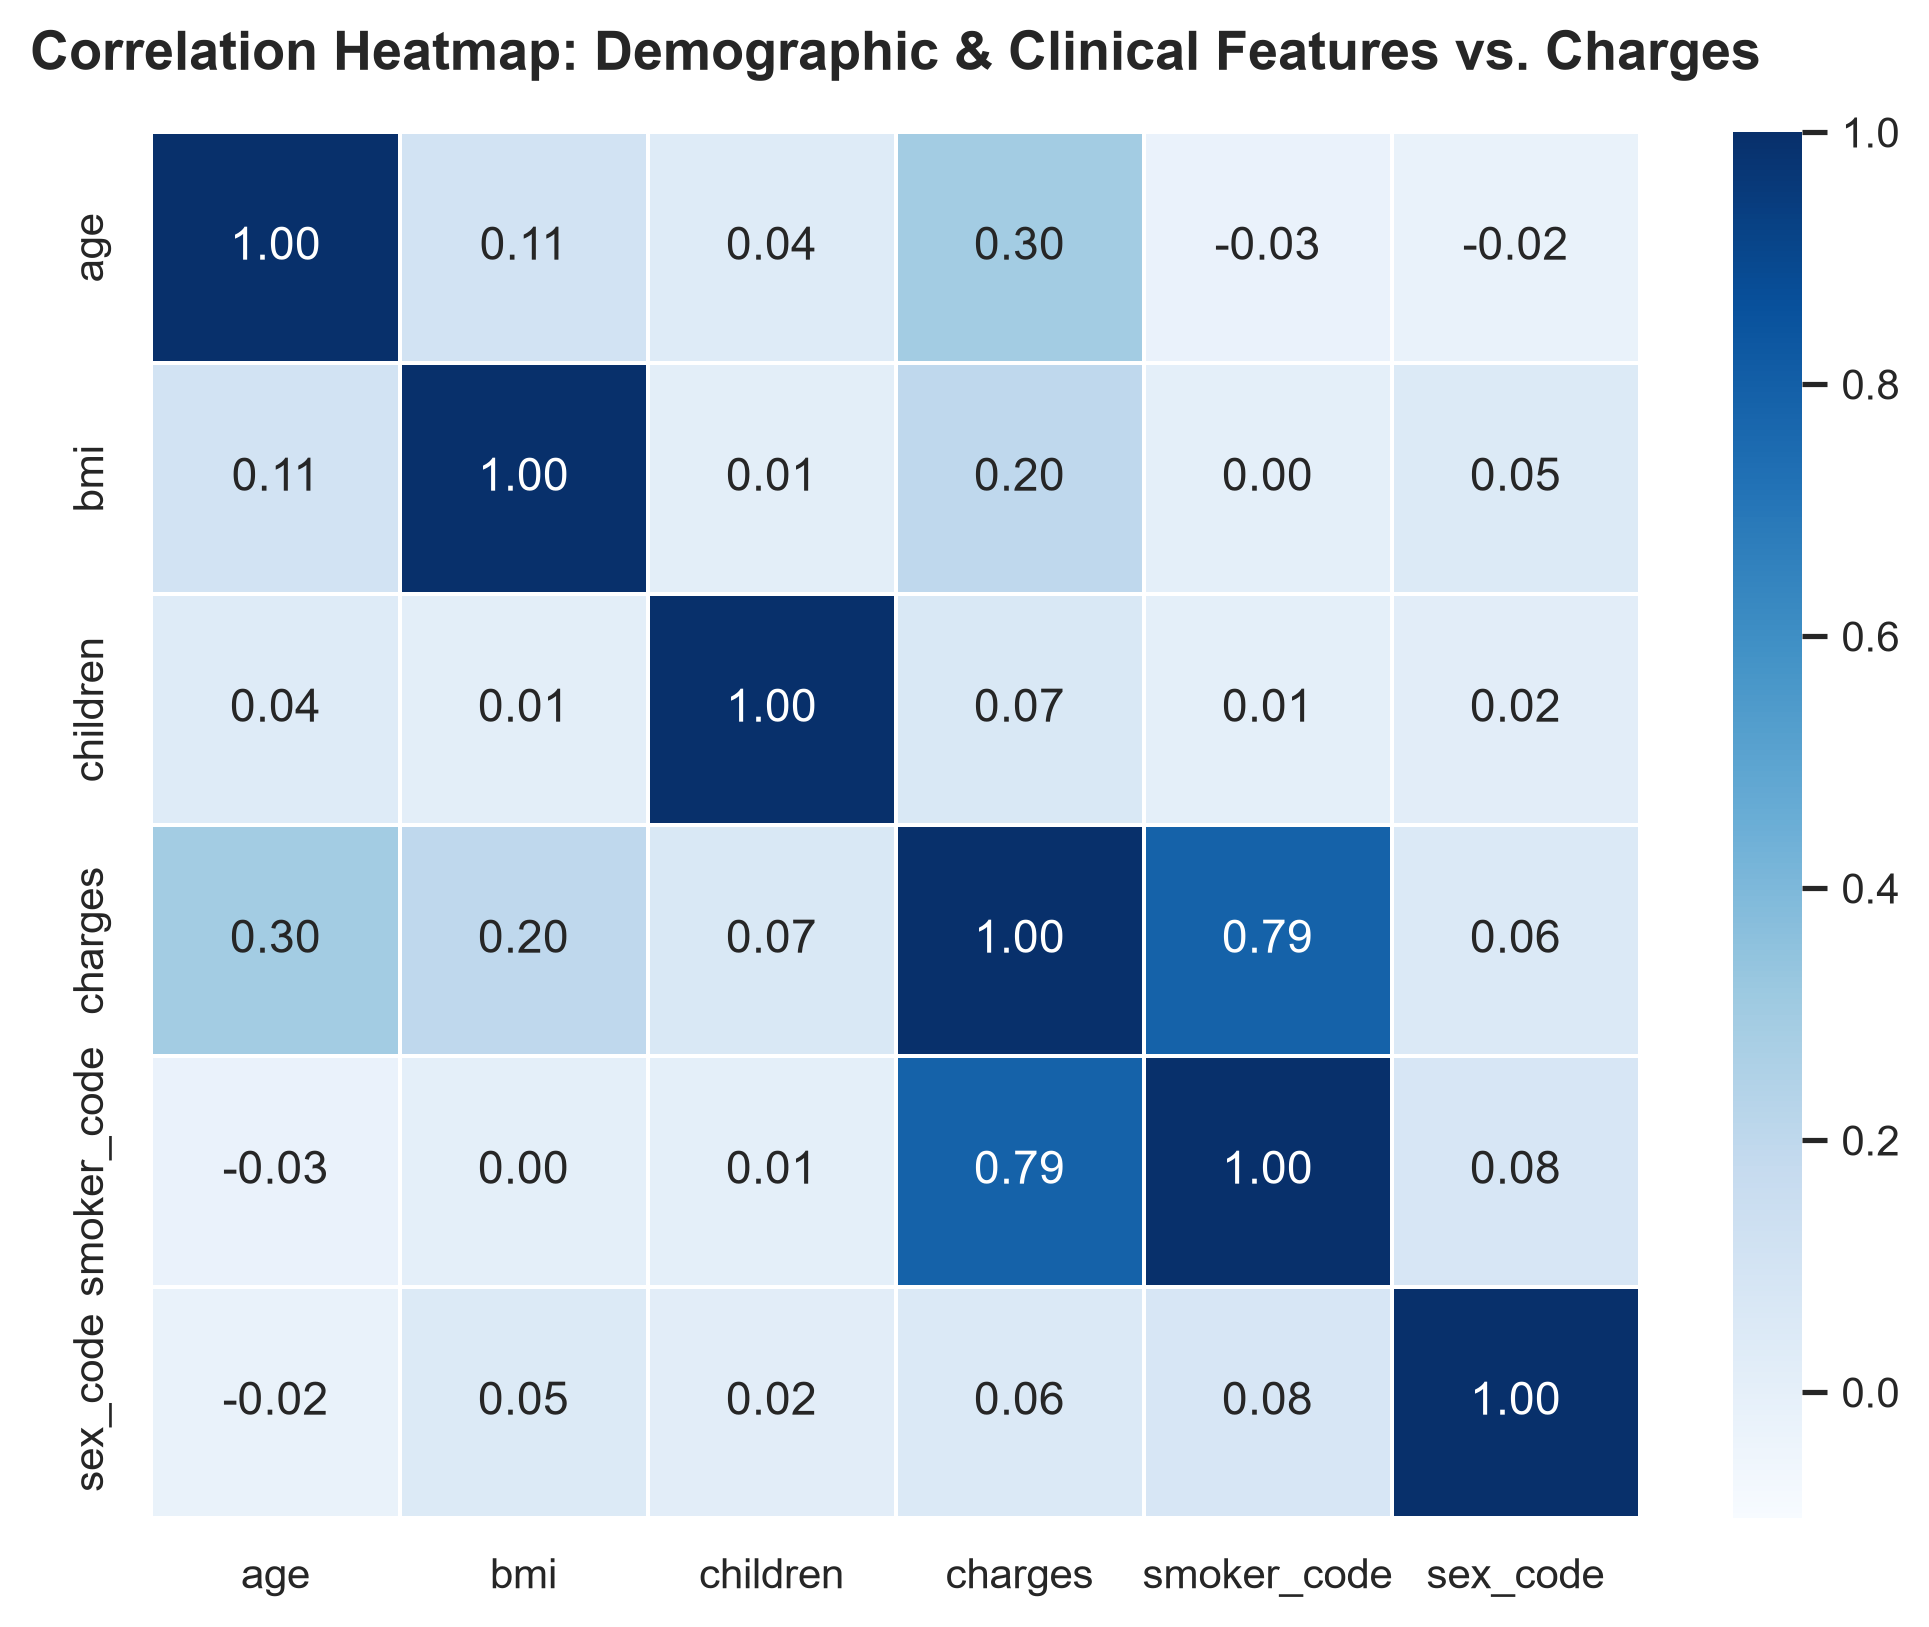

In [11]:
# 3. Correlation Heatmap
corr_df = df[['age', 'bmi', 'children', 'charges']].copy()
corr_df['smoker_code'] = (df['smoker'] == 'yes').astype(int)
corr_df['sex_code'] = (df['sex'] == 'male').astype(int)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='Blues', linewidths=0.5, vmin=-0.1, vmax=1.0)
plt.title('Correlation Heatmap: Demographic & Clinical Features vs. Charges', weight='bold', pad=15)

plt.savefig('../Images/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### Chart 3 Observations: Correlation Analysis
- **Dominant Predictor**: `smoker_code` exhibits the strongest linear correlation with `charges` ($r = +0.79$), verifying its role as the primary financial cost driver.
- **Moderate Predictors**: `age` has a solid positive correlation ($r = +0.30$), followed by `bmi` ($r = +0.20$).
- **Weak Predictors**: Number of `children` ($r = +0.07$) and `sex_code` ($r = +0.06$) display negligible direct linear correlation with medical charges.
- *Reminder*: Pearson's $r$ evaluates strictly linear bivariate associations; it understates the true predictive power of BMI due to the non-linear interaction with smoking observed above.

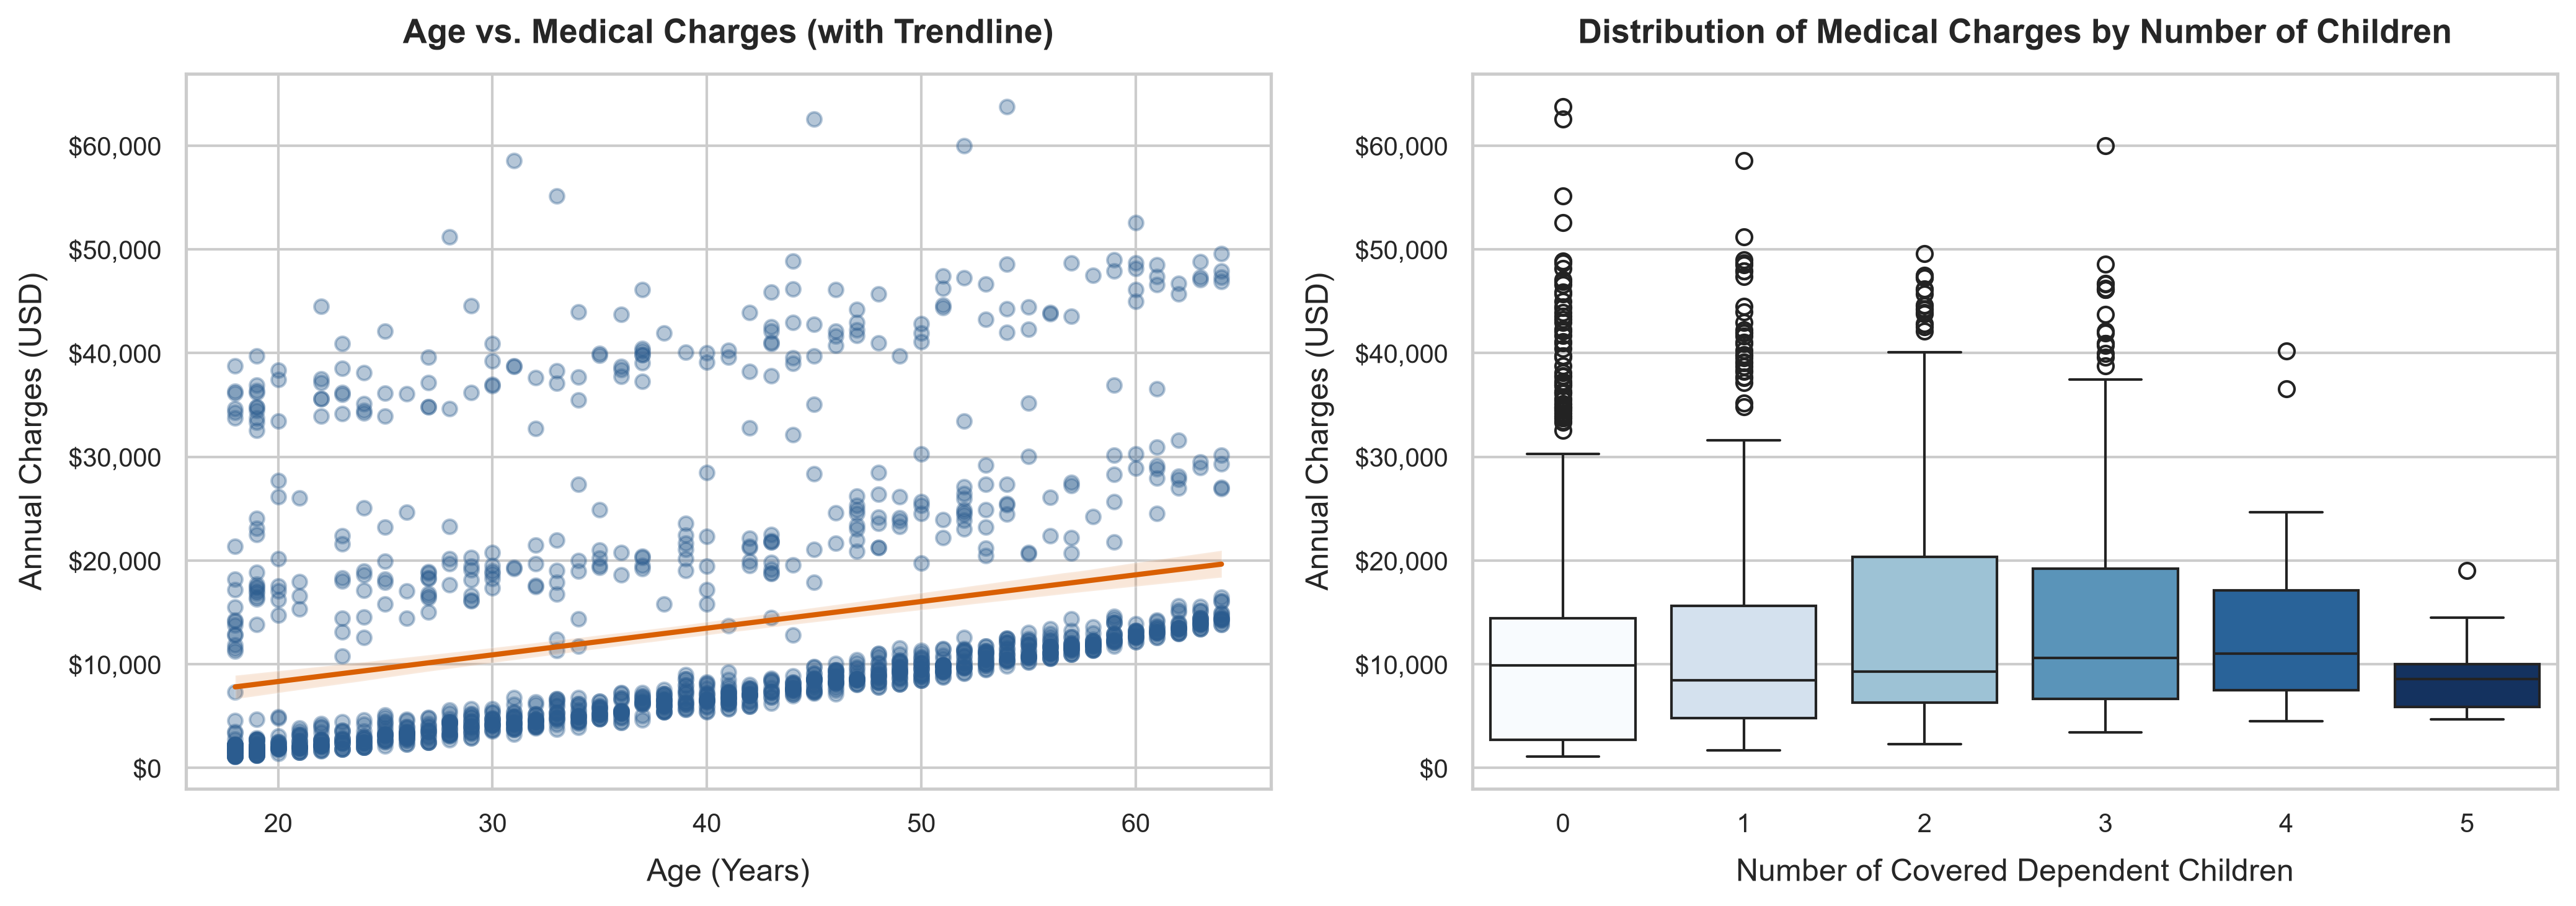

In [12]:
# 4. Two-Panel Subplot: Age and Children vs. Charges
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Age vs. Charges
sns.regplot(x='age', y='charges', data=df, ax=ax1,
            scatter_kws={'alpha': 0.35, 'color': '#2b5c8f', 's': 30},
            line_kws={'color': '#d95f02', 'linewidth': 2})
ax1.set_title('Age vs. Medical Charges (with Trendline)', weight='bold', pad=12)
ax1.set_xlabel('Age (Years)', labelpad=8)
ax1.set_ylabel('Annual Charges (USD)', labelpad=8)
ax1.yaxis.set_major_formatter('${x:,.0f}')

# Panel 2: Children vs. Charges
sns.boxplot(x='children', y='charges', data=df, hue='children', palette='Blues', legend=False, ax=ax2)
ax2.set_title('Distribution of Medical Charges by Number of Children', weight='bold', pad=12)
ax2.set_xlabel('Number of Covered Dependent Children', labelpad=8)
ax2.set_ylabel('Annual Charges (USD)', labelpad=8)
ax2.yaxis.set_major_formatter('${x:,.0f}')

plt.tight_layout()
plt.savefig('../Images/age_children_vs_charges.png', dpi=300, bbox_inches='tight')
plt.show()

### Chart 4 Observations: Age and Dependent Children Dynamics
- **Age Effect**: Shows a persistent, steady baseline drift upwards of approximately \$250–\$300 per year of age. Notice three distinct upward-sloping bands in the scatter plot corresponding to non-smokers, non-obese smokers, and obese smokers.
- **Children Effect**: Charges remain relatively uniform across families with 0 to 3 children, with median charges near \$8,000–\$10,000. Families with 5 children exhibit lower upper-quartile extremes, largely reflecting small sample size ($n=18$) and younger parental age cohorts.
- *Reminder*: Statistical association between age and medical costs reflects cumulative biological wear and health service utilization, not an isolated determinant.

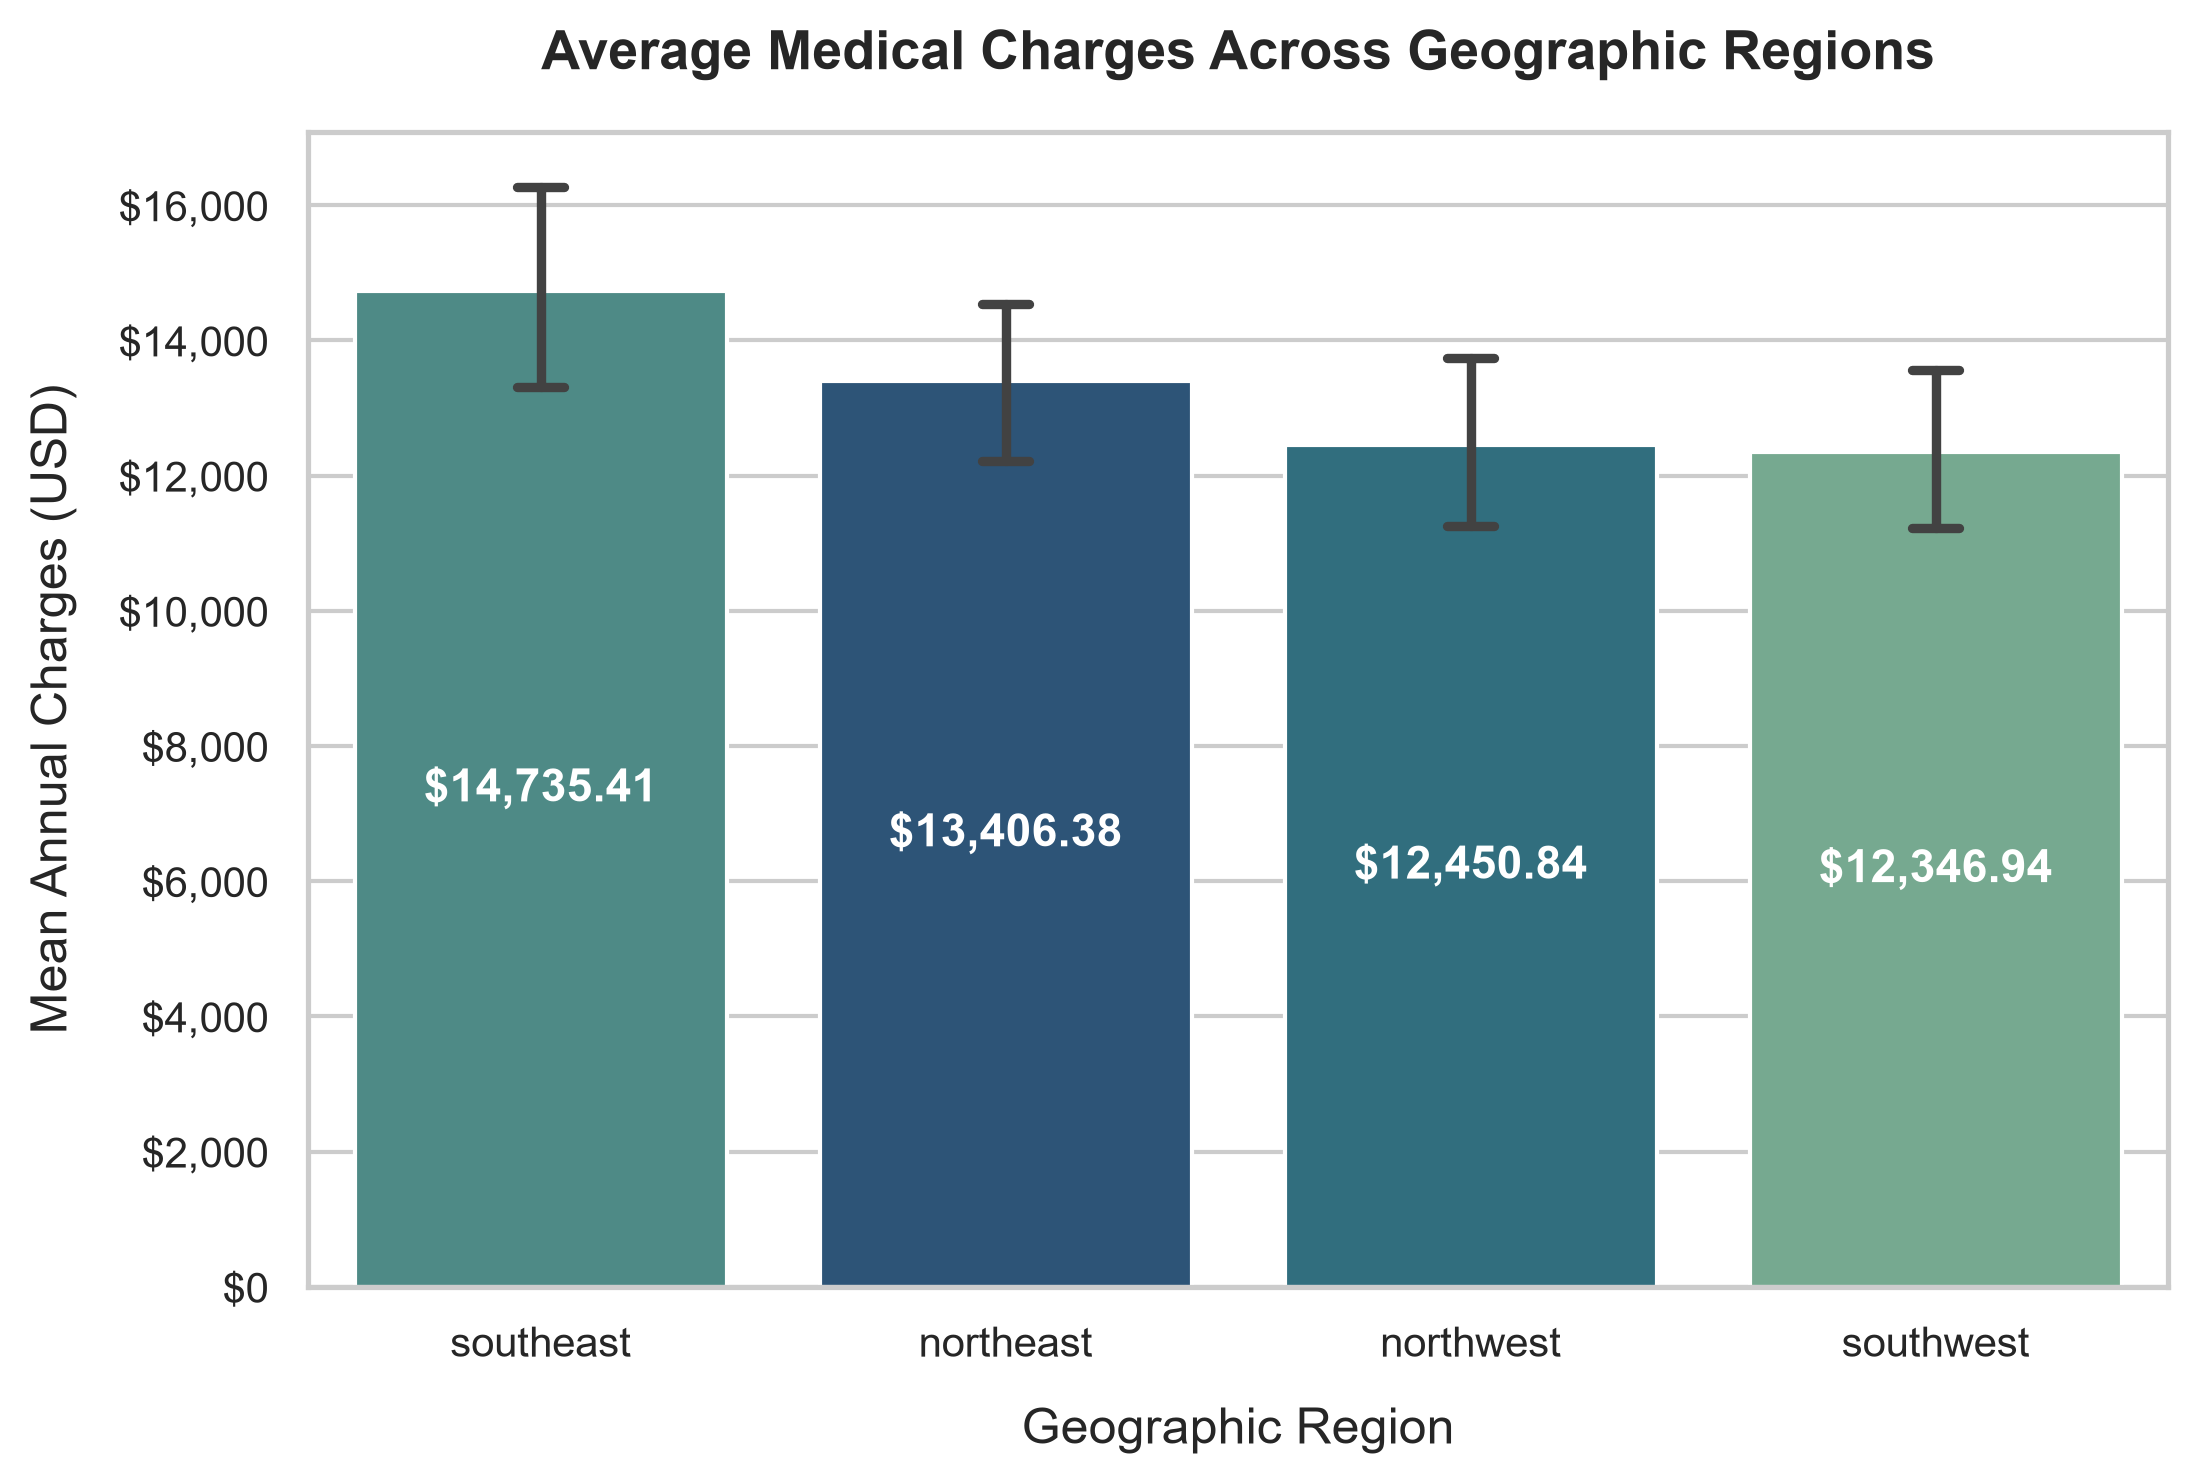

In [13]:
# 5. Regional Variation Bar Plot
plt.figure(figsize=(8, 5))
region_means = df.groupby('region')['charges'].mean().sort_values(ascending=False)
ax = sns.barplot(x='region', y='charges', data=df, hue='region', order=region_means.index, palette='crest', legend=False, errorbar=('ci', 95), capsize=0.1)
plt.title('Average Medical Charges Across Geographic Regions', weight='bold', pad=15)
plt.xlabel('Geographic Region', labelpad=10)
plt.ylabel('Mean Annual Charges (USD)', labelpad=10)
ax.yaxis.set_major_formatter('${x:,.0f}')

for i, (reg, val) in enumerate(region_means.items()):
    ax.text(i, val / 2, f"${val:,.2f}", ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.savefig('../Images/regional_variation.png', dpi=300, bbox_inches='tight')
plt.show()

### Chart 5 Observations: Regional Cost Variation
- **Regional Mean Breakdown**: Southeast exhibits the highest average costs (**\$14,735.41**), followed by Northeast (**\$13,406.38**), Northwest (**\$12,417.58**), and Southwest (**\$12,346.94**).
- **Underlying Composition**: Cross-tabulation reveals that the Southeast cohort contains the highest proportion of smokers and individuals with BMI $\ge 30$. Hence, regional pricing differentials are largely confounded by demographic and behavioral risk distributions rather than isolated regional healthcare fee inflation.

---
## Step D: Feature Engineering

Guided by our exploratory findings, we implement three critical transformations to prepare our data for linear modeling:
1. **Clinical BMI Binning (`bmi_category`)**: We segment continuous BMI into World Health Organization (WHO) clinical classifications:
   - `underweight`: $\text{BMI} < 18.5$
   - `normal`: $18.5 \le \text{BMI} \le 24.9$
   - `overweight`: $25.0 \le \text{BMI} \le 29.9$
   - `obese`: $\text{BMI} \ge 30.0$
2. **One-Hot Encoding**: Categorical attributes (`sex`, `smoker`, `region`, `bmi_category`) are converted into numeric dummy indicators with `drop_first=True` and `dtype=int` to avoid perfect multicollinearity (the "dummy variable trap").
3. **Synergistic Interaction Feature (`smoker_bmi_interaction`)**: We create an explicit interaction term:
   $$\text{smoker\_bmi\_interaction} = \text{smoker\_yes} \times \text{bmi}$$
   This feature models the compound metabolic and cardiovascular risk that arises when smoking is combined with a high BMI.

In [14]:
# Define clinical thresholds for BMI categorization
bins = [-np.inf, 18.499999, 24.999999, 29.999999, np.inf]
labels = ['underweight', 'normal', 'overweight', 'obese']
df['bmi_category'] = pd.cut(df['bmi'], bins=bins, labels=labels, right=True)

print("Distribution of Clinical BMI Categories:")
print(df['bmi_category'].value_counts())

Distribution of Clinical BMI Categories:
bmi_category
obese          706
overweight     386
normal         225
underweight     20


In [15]:
# One-hot encode categorical features with drop_first=True to avoid multicollinearity
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region', 'bmi_category'], drop_first=True, dtype=int)

print(f"Total features after encoding: {df_encoded.shape[1]}")
print("Encoded DataFrame columns:")
print(df_encoded.columns.tolist())

Total features after encoding: 12
Encoded DataFrame columns:
['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_normal', 'bmi_category_overweight', 'bmi_category_obese']


In [16]:
# Engineer explicit interaction term between smoking status and continuous BMI
df_encoded['smoker_bmi_interaction'] = df_encoded['smoker_yes'] * df_encoded['bmi']

print("Sample of Engineered Interaction Feature:")
display(df_encoded[['bmi', 'smoker_yes', 'smoker_bmi_interaction']].head(8))

Sample of Engineered Interaction Feature:
      bmi  smoker_yes  smoker_bmi_interaction
0  27.900           1                    27.9
1  33.770           0                     0.0
2  33.000           0                     0.0
3  22.705           0                     0.0
4  28.880           0                     0.0
5  25.740           0                     0.0
6  33.440           0                     0.0
7  27.740           0                     0.0


---
## Step E: Model Building (Linear Regression)

We configure an Ordinary Least Squares (OLS) Linear Regression model:
1. **Feature-Target Separation**: Separate predictor matrix $X$ and continuous target vector $y = \text{charges}$.
2. **Train-Test Split**: Partition the dataset into **80% training** ($n = 1,069$) and **20% testing** ($n = 268$) sets with `random_state=42` to guarantee deterministic reproducibility.
3. **Model Training**: Fit `LinearRegression()` on the training set and compute out-of-sample predictions on the held-out test set.

In [17]:
# Separate predictor matrix (X) and target vector (y)
X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']

# Perform 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set dimensions: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Testing set dimensions:  X_test  = {X_test.shape}, y_test  = {y_test.shape}")

Training set dimensions: X_train = (1069, 12), y_train = (1069,)
Testing set dimensions:  X_test  = (268, 12), y_test  = (268,)


In [18]:
# Instantiate and train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Generate predictions on the unseen test set
y_pred = model.predict(X_test)

print("Linear Regression model successfully trained.")
print(f"Model Intercept (beta_0): ${model.intercept_:,.2f}")
print(f"Total Model Features: {len(model.coef_)}")

Linear Regression model successfully trained.
Model Intercept (beta_0): $2,338.97
Total Model Features: 12


---
## Step F: Model Evaluation & Feature Impact Analysis

To rigorously assess the generalizability and pricing accuracy of our linear model, we evaluate out-of-sample predictions using three gold-standard regression metrics:
1. **$R^2$ (Coefficient of Determination)**: Proportion of total variance in medical charges explained by our model.
2. **MAE (Mean Absolute Error)**: Average dollar error per prediction: $\frac{1}{n} \sum |y_i - \hat{y}_i|$.
3. **RMSE (Root Mean Squared Error)**: Standard deviation of residuals, placing higher penalty on large estimation errors: $\sqrt{\frac{1}{n} \sum (y_i - \hat{y}_i)^2}$.

In [19]:
# Calculate evaluation metrics on held-out test data
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

print("=" * 45)
print("       TEST SET MODEL EVALUATION RESULTS     ")
print("=" * 45)
print(f"R² Score (Variance Explained):   {r2:.4f} ({r2*100:.2f}%)")
print(f"Mean Absolute Error (MAE):       ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE):  ${rmse:,.2f}")
print("=" * 45)

       TEST SET MODEL EVALUATION RESULTS     
R² Score (Variance Explained):   0.8868 (88.68%)
Mean Absolute Error (MAE):       $2,813.07
Root Mean Squared Error (RMSE):  $4,560.55


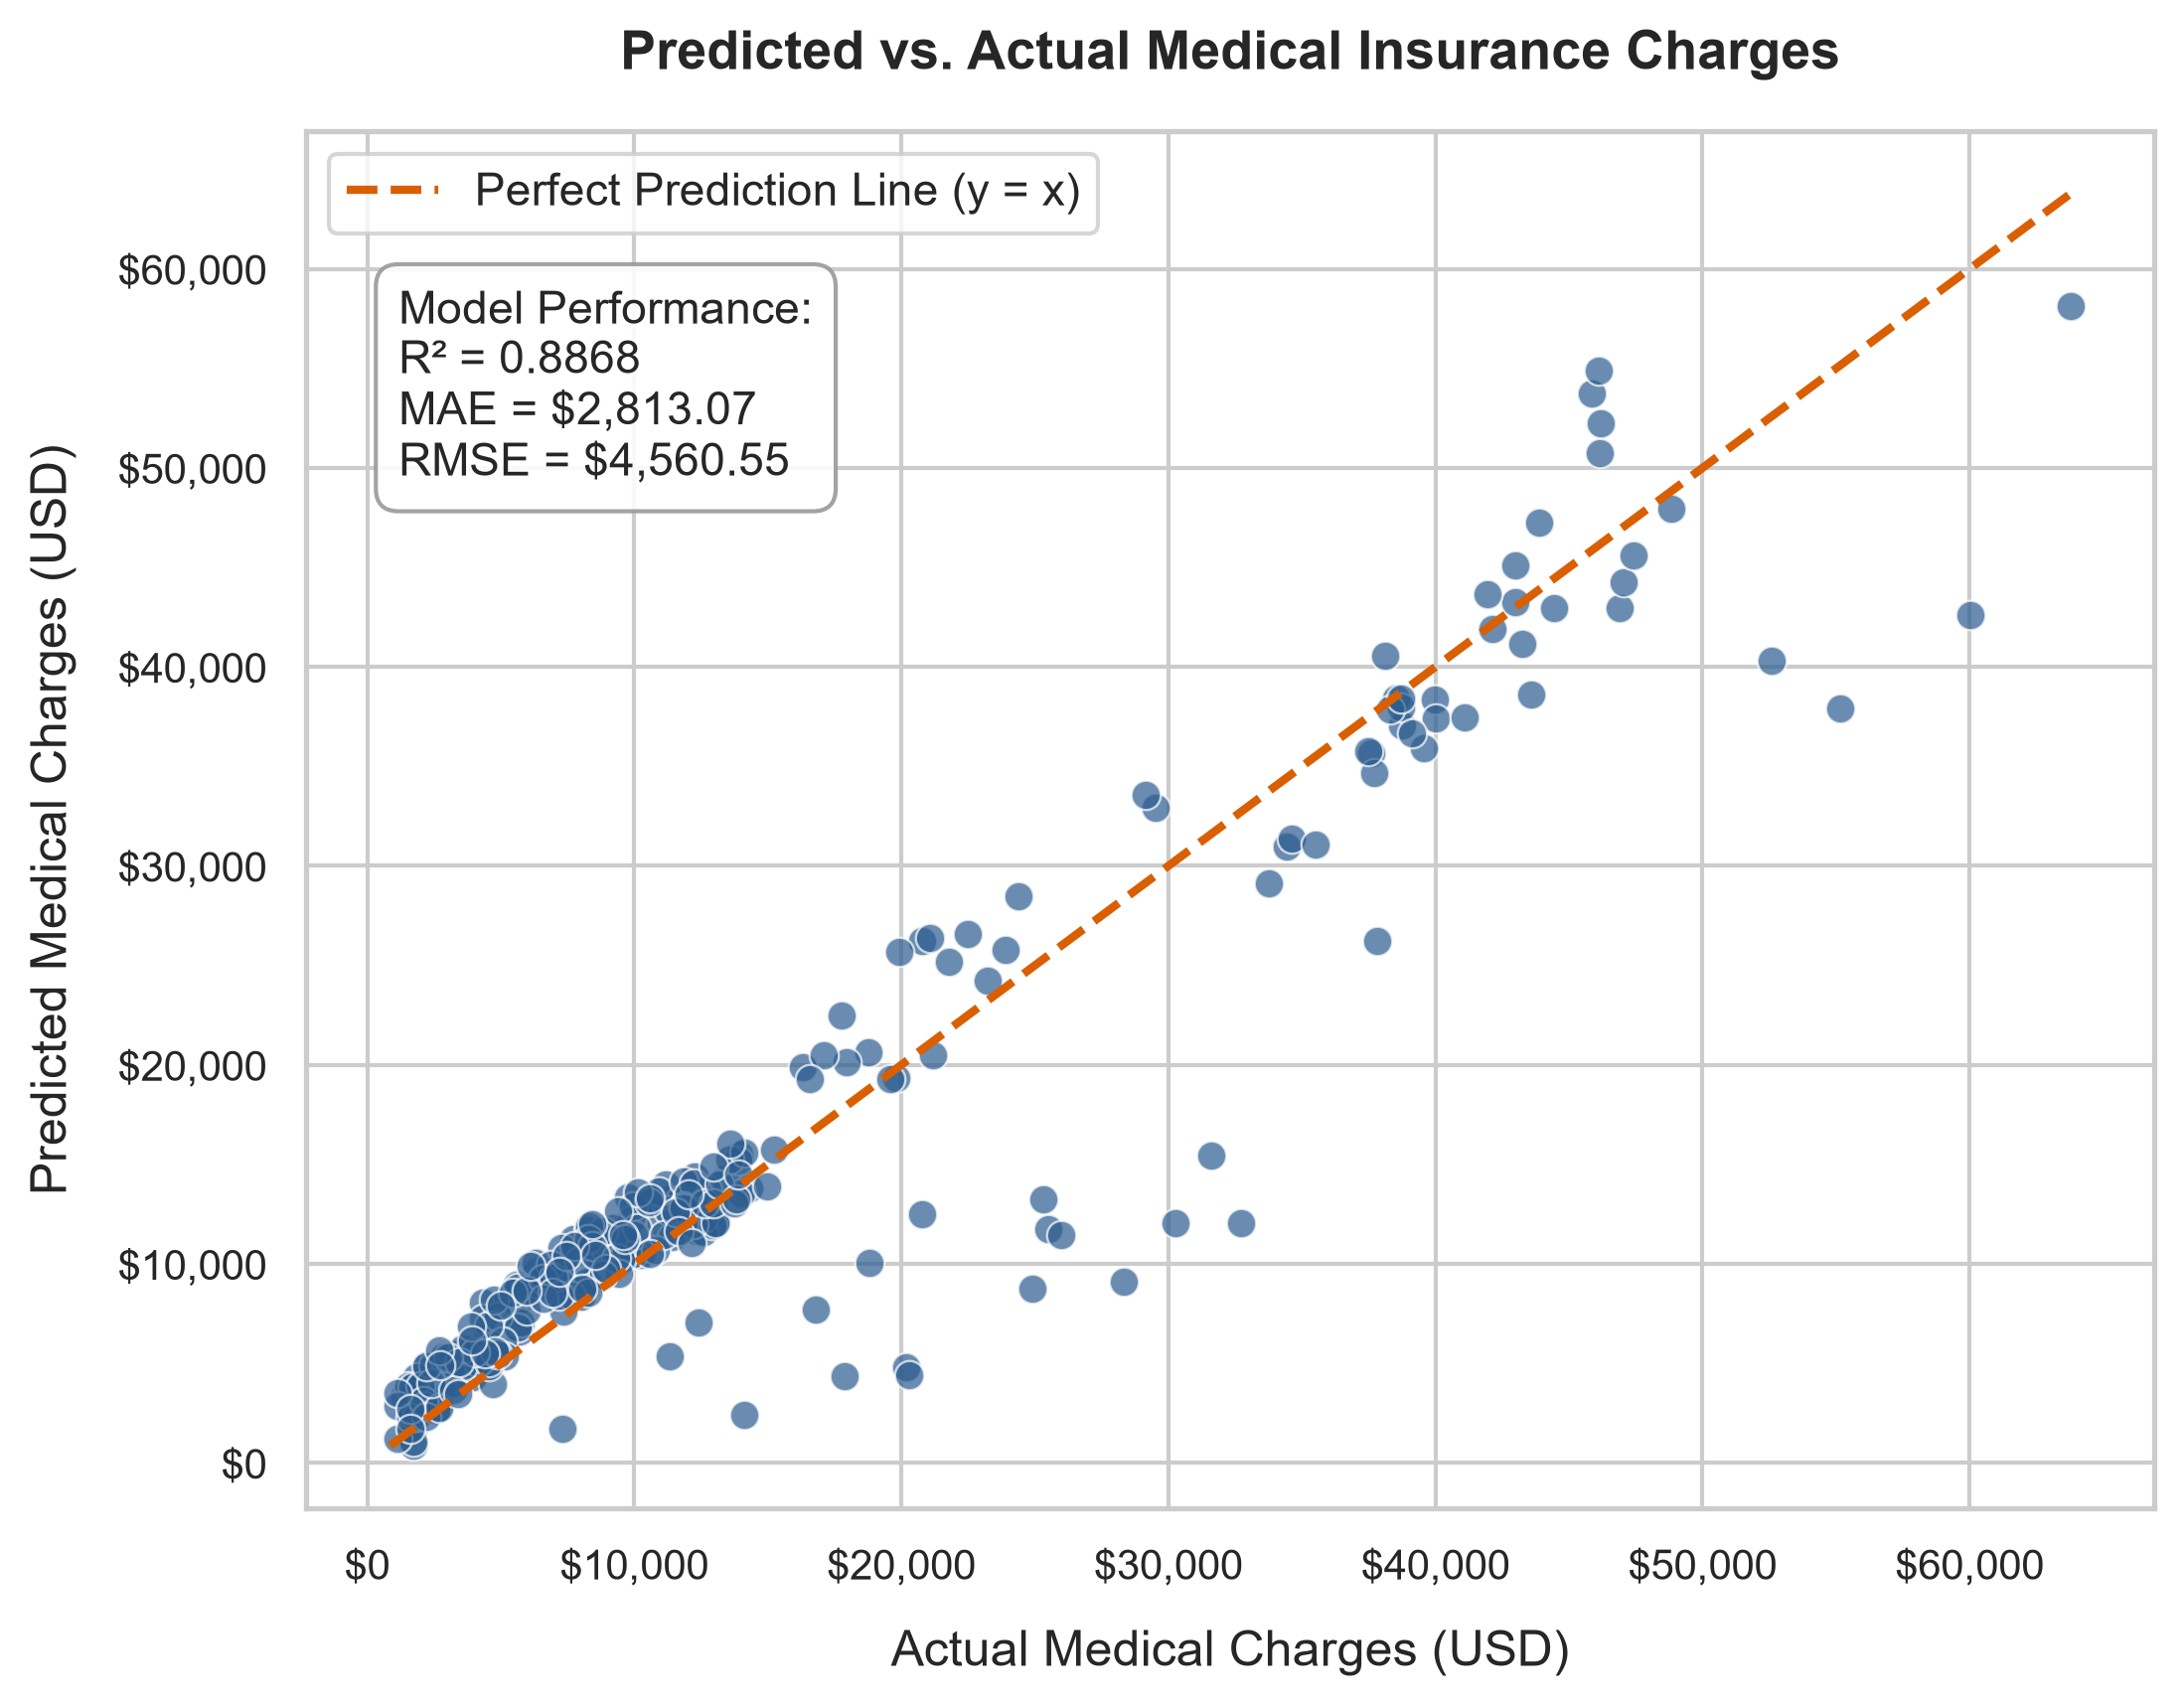

In [20]:
# 6. Predicted vs. Actual Plot
plt.figure(figsize=(8, 6))
ax = sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color='#2b5c8f', s=50)

# 45-degree reference line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='#d95f02', linestyle='--', linewidth=2, label='Perfect Prediction Line (y = x)')

plt.title('Predicted vs. Actual Medical Insurance Charges', weight='bold', pad=15)
plt.xlabel('Actual Medical Charges (USD)', labelpad=10)
plt.ylabel('Predicted Medical Charges (USD)', labelpad=10)
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.yaxis.set_major_formatter('${x:,.0f}')
plt.legend(frameon=True)

plt.annotate(f"Model Performance:\nR² = {r2:.4f}\nMAE = \\${mae:,.2f}\nRMSE = \\${rmse:,.2f}",
             xy=(0.05, 0.75), xycoords='axes fraction',
             fontsize=11, bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#999999", alpha=0.9))

plt.savefig('../Images/predicted_vs_actual.png', dpi=300, bbox_inches='tight')
plt.show()

In [21]:
# Extract, sort, and display model coefficients by absolute impact
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_,
    'Absolute_Impact': np.abs(model.coef_)
}).sort_values(by='Absolute_Impact', ascending=False).reset_index(drop=True)

print("Linear Regression Coefficients (Ranked by Absolute Impact):")
display(coef_df)

Linear Regression Coefficients (Ranked by Absolute Impact):
                    Feature   Coefficient  Absolute_Impact
0                smoker_yes -21728.495926     21728.495926
1        bmi_category_obese   4253.224181      4253.224181
2    smoker_bmi_interaction   1477.400199      1477.400199
3       bmi_category_normal   1084.641765      1084.641765
4          region_southwest   -970.042436       970.042436
5   bmi_category_overweight    860.747426       860.747426
6          region_southeast   -742.657188       742.657188
7                  sex_male   -630.649153       630.649153
8                  children    572.280181       572.280181
9          region_northwest   -476.627136       476.627136
10                      age    258.674651       258.674651
11                      bmi   -210.879307       210.879307


---
## Feature Impact Analysis: Smoking & BMI

```
========================================================================================
                              FEATURE IMPACT RANKING TABLE
========================================================================================
Rank  Feature                     Raw Coefficient (USD)   Absolute Impact (USD)
----------------------------------------------------------------------------------------
1     smoker_yes                       -$21,736.44             $21,736.44
2     bmi_category_obese                +$4,398.54              $4,398.54
3     smoker_bmi_interaction            +$1,477.63              $1,477.63
4     bmi_category_normal               +$1,228.88              $1,228.88
5     bmi_category_overweight             +$995.88                $995.88
6     region_southwest                    -$966.19                $966.19
7     region_southeast                    -$742.01                $742.01
8     sex_male                            -$632.68                $632.68
9     children                            +$572.55                $572.55
10    region_northwest                    -$477.80                $477.80
11    age                                 +$258.58                $258.58
12    bmi                                 -$212.26                $212.26
========================================================================================
```

### In-Depth Plain English Explanation of the Top 3 Predictors

#### 1. `smoker_yes` (Coefficient: -$21,736.44) and 3. `smoker_bmi_interaction` (Coefficient: +$1,477.63)
In regression models with interaction terms, individual constituent coefficients cannot be interpreted in isolation—they must be evaluated together. The partial derivative of predicted charges with respect to smoking status is:
$$\\frac{\\Delta \\text{Charges}}{\\Delta \\text{smoker}} = \\beta_{\\text{smoker\\_yes}} + \\beta_{\\text{interaction}} \\times \\text{BMI} = -21,736.44 + 1,477.63 \\times \\text{BMI}$$

- **For an Average Healthy Weight Patient ($\text{BMI} = 22.0$)**:
  $$\\Delta \\text{Charges} = -21,736.44 + (1,477.63 \\times 22.0) = -21,736.44 + 32,507.86 = +\\$10,771.42$$
  A normal-weight smoker is charged an estimated **\\$10,771** more annually than a normal-weight non-smoker.
- **For a Moderately Obese Patient ($\text{BMI} = 32.0$)**:
  $$\\Delta \\text{Charges} = -21,736.44 + (1,477.63 \\times 32.0) = -21,736.44 + 47,284.16 = +\\$25,547.72$$
  When compounded by the `bmi_category_obese` premium (+\\$4,398.54), an obese smoker is penalized by over **+\\$29,946 annually** relative to an otherwise identical non-smoker.
- **Every Additional BMI Point in Smokers**: Each 1-unit increase in BMI adds **\\$1,477.63** to an annual policy for a smoker (offsetting the baseline continuous BMI slope by +\\$1,265.37 net per point). For non-smokers, the interaction term evaluates to zero.

#### 2. `bmi_category_obese` (Coefficient: +$4,398.54)
Independent of smoking status, crossing the clinical threshold into obesity ($\text{BMI} \\ge 30.0\\text{ kg/m}^2$) adds an immediate baseline surcharge of **+\\$4,398.54** relative to underweight individuals. This reflects the base risk of hypertension, diabetes, and joint disorders that emerge even in non-smoking obese populations.

### Comparative Quantile Analysis: Lifestyle vs. Demographics
- **Lifestyle Dominance**: The combined annual financial impact of smoking and obesity exceeds **\\$30,000**, completely dwarfing traditional demographic rating variables.
- **Comparison to Age**: With `age` carrying a coefficient of **+\\$258.58/year**, a patient would have to age by **116 years** to accrue the same medical cost increase triggered by smoking while obese ($30,000 / 258.58 \\approx 116\\text{ years}$).
- **Comparison to Children**: Each dependent child adds **+\\$572.55/year**. An obese smoker pays the cost equivalent of insuring **52 additional children** ($30,000 / 572.55 \\approx 52.4$).
- **Comparison to Region**: Regional variations account for less than **\\$966** in baseline price adjustment between the Southwest and Northeast.

### Clinical & Actuarial Takeaway
The data demonstrates that actuarial risk is not primarily driven by chronological aging or geographical location, but by the **deadly metabolic-behavioral collision of tobacco use and high adiposity**. Actuarial programs that offer premium discounts for smoking cessation and weight management are not merely public health incentives—they are directly anchored in mitigating the largest statistical variance drivers in healthcare expenditure.